# Figure 2

In [98]:
from pathlib import Path

current_file_path = Path().resolve().parent
current_file_path

PosixPath('/home/mag/variance-analysis')

## Figure 2b

This method provides an unbiased estimate of the variance explained by individual variables with discrete sampling.

In [213]:
import numpy as np

def rotated_tuning(s1, s2, c, theta, sigma, amp, wrap=False):
    if wrap:
        d1 = ((s1 - c + 0.5) % 1.0) - 0.5 
        d2 = ((s2 - c + 0.5) % 1.0) - 0.5
    else:
        d1 = s1 - c
        d2 = s2 - c
        
    ct, st = np.cos(theta), np.sin(theta)
    u = d1 * ct - d2 * st
    
    return amp * np.exp(-0.5 * (u / sigma) ** 2)

def get_rot_counts(seed=413, theta_deg=90.):
    min_rate = 5.0
    max_rate = 35.0
    
    mu_diff, sigma = 0.0, 0.1
    mu = 0.4
    lo, hi = 0.0, 1.0
    num_bins = 15
    N = 900
           
    use_wrap = False
    
    beta0     = np.log(min_rate)
    amplitude = np.log(max_rate) - beta0
    theta = np.deg2rad(theta_deg)
    
    rng = np.random.default_rng(seed)
    s1 = rng.uniform(lo, hi, size=N)
    s2 = rng.uniform(lo, hi, size=N)
    
    bin_edges = np.linspace(lo, hi, num_bins + 1)

    bin_width = (hi - lo) / num_bins
    s1_bin = np.clip(((s1 - lo) / bin_width).astype(int), 0, num_bins - 1)
    s2_bin = np.clip(((s2 - lo) / bin_width).astype(int), 0, num_bins - 1)
    
    s1 = lo + (s1_bin + 0.5) * bin_width  
    s2 = lo + (s2_bin + 0.5) * bin_width
    
    tuning = rotated_tuning(s1, s2, c=mu, theta=theta, sigma=sigma, amp=amplitude, wrap=use_wrap)
    
    rates  = np.exp(beta0 + tuning)
    spike_counts = rng.poisson(rates)
    return spike_counts, (s1, s2)


spike_counts, (s1, s2) = get_rot_counts(seed=413)

num_bins = 15
lo, hi = 0.0, 1.0
bin_edges = np.linspace(lo, hi, num_bins + 1)
occ, _, _ = np.histogram2d(s1, s2, bins=[bin_edges, bin_edges])
spk, _, _ = np.histogram2d(s1, s2, bins=[bin_edges, bin_edges], weights=spike_counts)
rate_map = np.divide(spk, occ, out=np.zeros_like(spk), where=occ > 0)


In [214]:
def build_raw_visits(s1_t, s2_t, counts, tau, num_bins, bin_edges):
    '''
    Get a list of all of the time bin visits and the associated spike rates for
    each spatial bin -- "raw" rate maps.
    '''
    visit_rates = counts.astype(float) / float(tau)

    i = np.digitize(s1_t, bin_edges) - 1
    j = np.digitize(s2_t, bin_edges) - 1
    in_range = (i >= 0) & (i < num_bins) & (j >= 0) & (j < num_bins)
    i = i[in_range]
    j = j[in_range]
    visit_rates = visit_rates[in_range]

    occ_visits, _, _ = np.histogram2d(
        s1_t[in_range], s2_t[in_range], bins=[bin_edges, bin_edges]
    )
    occ_visits = occ_visits.astype(int)

    max_bin_occ = int(occ_visits.max()) if occ_visits.size else 0

    bin_lists = [[[] for _ in range(num_bins)] for _ in range(num_bins)]
    for idx_visit, (ii, jj) in enumerate(zip(i, j)):
        bin_lists[ii][jj].append(idx_visit)

    raw_visits = np.full((num_bins, num_bins, max_bin_occ), np.nan)
    
    for ii in range(num_bins):
        for jj in range(num_bins):
            idxs = bin_lists[ii][jj]
            if not idxs:
                continue

            take = len(visit_rates[idxs])
            raw_visits[ii, jj, :take] = visit_rates[idxs][:take]

    return raw_visits, occ_visits

In [215]:
gt_ev_y[0]

1.0

In [216]:
def ground_truth_evs(theta_deg, *, lo=0.0, hi=1.0, mu=0.4, sigma=0.1,
                     min_rate=5.0, max_rate=35.0, use_wrap=False, grid=256):
    ev_x = theta_deg/90
    ev_y = 1-ev_x
    return float(ev_x), float(ev_y)

gt_ev_x = np.zeros(r)
gt_ev_y = np.zeros(r)
for i, theta in enumerate(rots):
    evx, evy = ground_truth_evs(theta_deg=theta, lo=lo, hi=hi, mu=0.4, sigma=0.1,
                                min_rate=5.0, max_rate=35.0, use_wrap=False, grid=256)
    gt_ev_x[i] = evx
    gt_ev_y[i] = evy

In [217]:
gt_ev_y[1]

0.7222222222222222

In [220]:
from src.explained_variance import *
from scipy.ndimage import zoom
from tqdm import tqdm

# there's some variance in the dataset and also between splitting the two folds

n_splits = 100

rots = [0, 25, 45]
r = len(rots)
rate_maps    = [None] * r

ev_s1 = np.zeros((r, n_splits))
ev_s2 = np.zeros((r, n_splits))

for rot in range(r):
    for s in tqdm(range(n_splits)):
        counts, (s1, s2) = get_rot_counts(seed=s, theta_deg=rots[rot])
        occ,  _, _ = np.histogram2d(s1, s2, bins=[bin_edges, bin_edges])
        spk,  _, _ = np.histogram2d(s1, s2, bins=[bin_edges, bin_edges], weights=counts)
        rate_map = np.divide(spk, occ, out=np.zeros_like(spk), where=occ > 0)
        rate_maps[rot] = rate_map
    
        raw_visits, _ = build_raw_visits(s1, s2, counts, 1., num_bins, bin_edges)
        _, fold0, fold1, _, _ = get_splits(raw_visits[:, :, :, np.newaxis], seed=s)

        fold0_smooth = nan_aware_gaussian_filter(fold0[:, :, 0], sigma=3)
        fold1_smooth = nan_aware_gaussian_filter(fold1[:, :, 0], sigma=3)

        est_s1 = quantify_variance(fold0_smooth, fold1_smooth, axis=0, normalize=False)[0]
        est_s2 = quantify_variance(fold0_smooth, fold1_smooth, axis=1, normalize=False)[0]

        global_mean_test = np.nanmean(fold0_smooth)
        global_mean_train = np.nanmean(fold1_smooth)
        
        total_var_test = np.nansum((fold0_smooth - global_mean_test)**2)
        total_var_train = np.nansum((fold1_smooth - global_mean_train)**2)
        total_var = 0.5 * (total_var_test + total_var_train)
        
        if total_var > 0:
            ev_s1[rot, s] = est_s1 / (est_s1 + est_s2)
            ev_s2[rot, s] = est_s2 / (est_s1 + est_s2)
        else:
            ev_s1[rot, s] = 0
            ev_s2[rot, s] = 0



100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 100/100 [00:00<00:00, 182.32it/s]


/tmp/ipykernel_984450/945338920.py:51: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


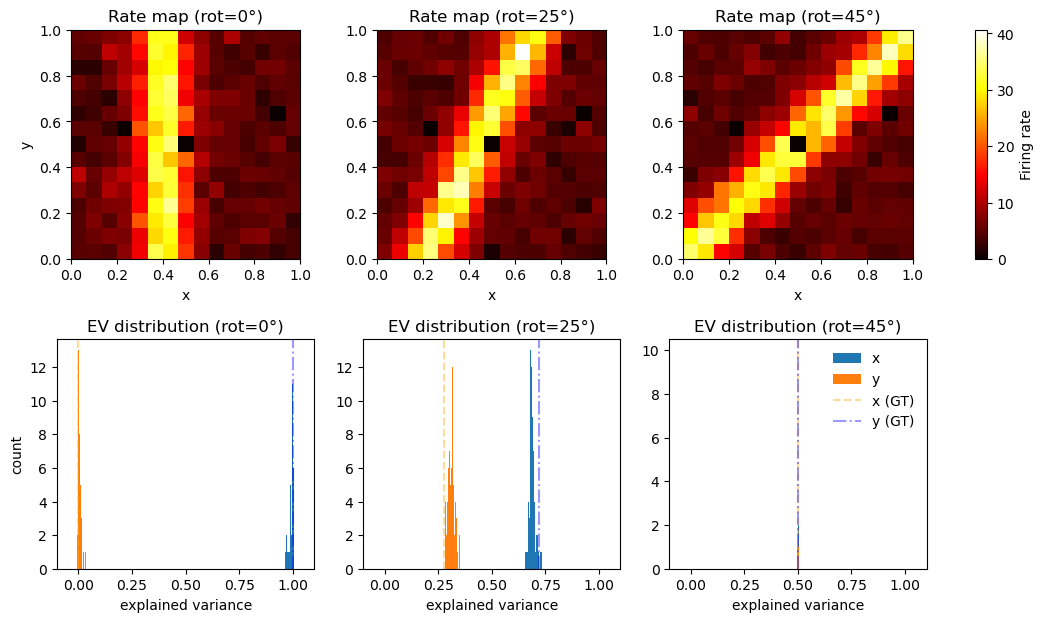

In [221]:
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(12, 7))
gs = fig.add_gridspec(nrows=2, ncols=r + 1,
                      width_ratios=[1]*r + [0.045],
                      height_ratios=[1, 1],
                      wspace=0.25, hspace=0.35)

vmin = min(np.nanmin(m) for m in rate_maps)
vmax = max(np.nanmax(m) for m in rate_maps)
im_handles = []
for i, theta in enumerate(rots):
    ax = fig.add_subplot(gs[0, i])
    im = ax.imshow(rate_maps[i].T, origin='lower', aspect='equal',
                   extent=[lo, hi, lo, hi], cmap='hot', vmin=vmin, vmax=vmax)
    im_handles.append(im)
    ax.set_title(f"Rate map (rot={theta}°)")
    if i == 0: ax.set_ylabel("y")
    ax.set_xlabel("x")

cax = fig.add_subplot(gs[0, -1])
fig.colorbar(im_handles[0], cax=cax, label='Firing rate')

rightmost_ax = None
legend_handles = None

for i, theta in enumerate(rots):
    ax = fig.add_subplot(gs[1, i])
    if i == r - 1:
        rightmost_ax = ax 

    h1 = ax.hist(ev_s1[i, :], bins=30, alpha=1, histtype='stepfilled', label='x')
    h2 = ax.hist(ev_s2[i, :], bins=30, alpha=1, histtype='stepfilled', label='y')

    ax.set_xlim(-0.1, 1.1)

    lx = ax.axvline(gt_ev_x[i], linestyle='--', linewidth=1.5, label='x (GT)', color='orange', alpha=0.4)
    ly = ax.axvline(gt_ev_y[i], linestyle='-.', linewidth=1.5, label='y (GT)', color='blue', alpha=0.4)

    ax.set_title(f"EV distribution (rot={theta}°)")
    if i == 0: ax.set_ylabel("count")
    ax.set_xlabel("explained variance")

    if i == r - 1:
        legend_handles = [h1[2][0], h2[2][0], lx, ly]

if (rightmost_ax is not None) and (legend_handles is not None):
    rightmost_ax.legend(legend_handles, ['x', 'y', 'x (GT)', 'y (GT)'],
                        frameon=False, loc='upper right')

plt.tight_layout()
plt.show()


## Figure 2b, extended

This method incurs a small positive bias through binning a continuous variable. This is because:

(i) within-bin curvature makes the bin means a biased proxy for the underlying rate, and

(ii) squared-error terms and heteroskedastic occupancy make the cross-validated estimator slightly upward-biased.

We show this effect in this notebook and demonstrate that it's mitigated with a smoothing and upsampling procedure.

In [222]:
'''
Make a random walk across the space to simulate mouse trajectory.
'''

seed = 413
rng = np.random.default_rng(seed)

lo, hi = 0.0, 1.0
n_ts = 1500
step = 0.04           
ang_sigma = 0.9

positions = np.zeros((n_ts, 3), dtype=float)

positions[0, 0] = 0.0
positions[0, 1] = rng.random() 
positions[0, 2] = rng.random() 
ang = rng.uniform(0, 2*np.pi)  

for t in range(1, n_ts):
    ang += rng.normal(0.0, ang_sigma)
    ang = (ang + np.pi) % (2*np.pi) - np.pi

    x_prev, y_prev = positions[t-1, 1], positions[t-1, 2]
    x = x_prev + np.cos(ang) * step
    y = y_prev + np.sin(ang) * step

    if x < lo:
        x = 2*lo - x      
        ang = np.pi - ang 
    elif x > hi:
        x = 2*hi - x
        ang = np.pi - ang

    if y < lo:
        y = 2*lo - y
        ang = -ang
    elif y > hi:
        y = 2*hi - y
        ang = -ang

    ang = (ang + np.pi) % (2*np.pi) - np.pi

    positions[t, 0] = t
    positions[t, 1] = x
    positions[t, 2] = y


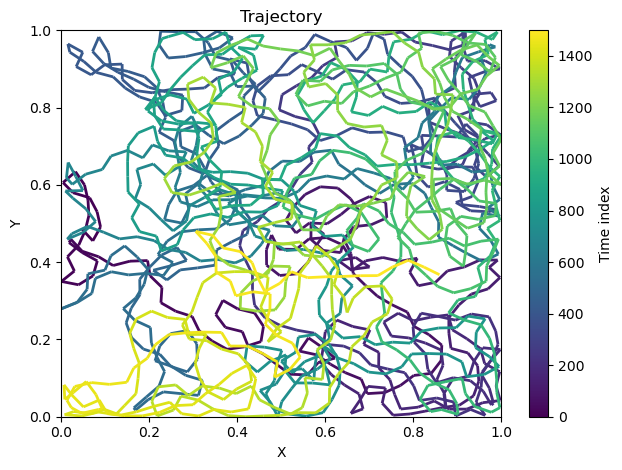

In [223]:
from matplotlib.collections import LineCollection
import numpy as np

x = positions[:, 1]
y = positions[:, 2]
timesteps = positions[:, 0]

# Build line segments between points
points = np.array([x, y]).T.reshape(-1, 1, 2)
segments = np.concatenate([points[:-1], points[1:]], axis=1)

lc = LineCollection(segments, cmap='viridis', norm=plt.Normalize(timesteps.min(), timesteps.max()))
lc.set_array(timesteps)
lc.set_linewidth(2)

fig, ax = plt.subplots()
line = ax.add_collection(lc)
cbar = fig.colorbar(line, ax=ax)
cbar.set_label("Time index")

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_title("Trajectory")

plt.tight_layout()
plt.show()


In [260]:
'''
Set up a simulated neuron with a Gaussian tuning curve in 1 dimension.
'''

def column_tuning(a, mu, sigma, amp):
    delta = np.abs(a - mu)
    return amp * np.exp(-0.5 * (delta / sigma)**2)

def get_counts(
    num_bins=20, 
    min_rate=5,
    max_rate=25,
    mu=0.4,
    sigma=0.2,
    tau=2,
    seed=413
):
    '''
    Get the number of spikes per time bin from a simulated neuron.
    '''

    rng = np.random.default_rng(seed)
    
    ts = positions[:, 0]
    s1, s2 = positions[:, 1], positions[:, 2]
    
    t0, t1 = float(ts[0]), float(ts[-1])
    base_time = np.arange(t0, t1, tau) 
    
    '''
    basically: you're evaluating a stimulus at the left side of the time bin (because 
    that's the position at which you start recording neurons for that time bin) and 
    then that time bin gets counted in your stimulus bin. this is what induces some 
    variation. fixing this point at which we evaluate the function to the center of 
    the spatial bin means this simulated neuron now has discrete tuning.
    '''
    
    idx = np.clip(np.searchsorted(ts, base_time, side='left'), 0, len(ts)-1)
    s1_t = s1[idx]
    s2_t = s2[idx]
    
    beta0     = np.log(min_rate)
    amplitude = np.log(max_rate) - beta0
    
    tuning = column_tuning(s1_t, mu, sigma, amplitude)
    lam_t  = np.exp(beta0 + tuning)           
    lam_t  = np.clip(lam_t, 0.0, None)
    
    lam_dt = lam_t * tau                       
    counts = rng.poisson(lam_dt)

    return counts, (s1_t, s2_t)

num_bins = 20

counts, (s1_t, s2_t) = get_counts(num_bins=num_bins)

bin_edges = np.linspace(lo, hi, num_bins + 1)

occ_seconds, _, _ = np.histogram2d(
    s1_t, s2_t, bins=[bin_edges, bin_edges],
    weights=np.full_like(s1_t, fill_value=2, dtype=float)
)

spk_counts, _, _ = np.histogram2d(
    s1_t, s2_t, bins=[bin_edges, bin_edges],
    weights=counts.astype(float)
)

rate_map = np.divide(
    spk_counts, occ_seconds,
    out=np.full_like(spk_counts, np.nan, dtype=float),
    where=occ_seconds > 0
)


In [261]:
'''
Now we make a discrete version.
'''

def get_counts_discrete(s1_t, s2_t, bin_edges, tau=2, seed=413):
    rng = np.random.default_rng(seed)
    
    mu = 0.4
    sigma = 0.2
    min_rate = 5.0
    max_rate = 25
    bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])
    i1 = np.clip(np.digitize(s1_t, bin_edges) - 1, 0, num_bins - 1)
    i2 = np.clip(np.digitize(s2_t, bin_edges) - 1, 0, num_bins - 1)
    s1_d = bin_centers[i1]
    s2_d = bin_centers[i2]

    beta0     = np.log(min_rate)
    amplitude = np.log(max_rate) - beta0
    tuning_d = column_tuning(s1_d, mu, sigma, amplitude)
    lam_t_d  = np.exp(beta0 + tuning_d)           
    lam_t_d  = np.clip(lam_t_d, 0.0, None)
    
    lam_dt_d = lam_t_d * tau                       
    counts_d = rng.poisson(lam_dt_d)
    
    return counts_d, (s1_d, s2_d)

counts_d, (s1_d, s2_d) = get_counts_discrete(s1_t, s2_t, bin_edges)

occ_seconds_d, _, _ = np.histogram2d(
    s1_d, s2_d, bins=[bin_edges, bin_edges],
    weights=np.full_like(s1_d, fill_value=2, dtype=float)
)

spk_counts_d, _, _ = np.histogram2d(
    s1_d, s2_d, bins=[bin_edges, bin_edges],
    weights=counts_d.astype(float)
)

rate_map_d = np.divide(
    spk_counts_d, occ_seconds_d,
    out=np.full_like(spk_counts_d, np.nan, dtype=float),
    where=occ_seconds_d > 0
)


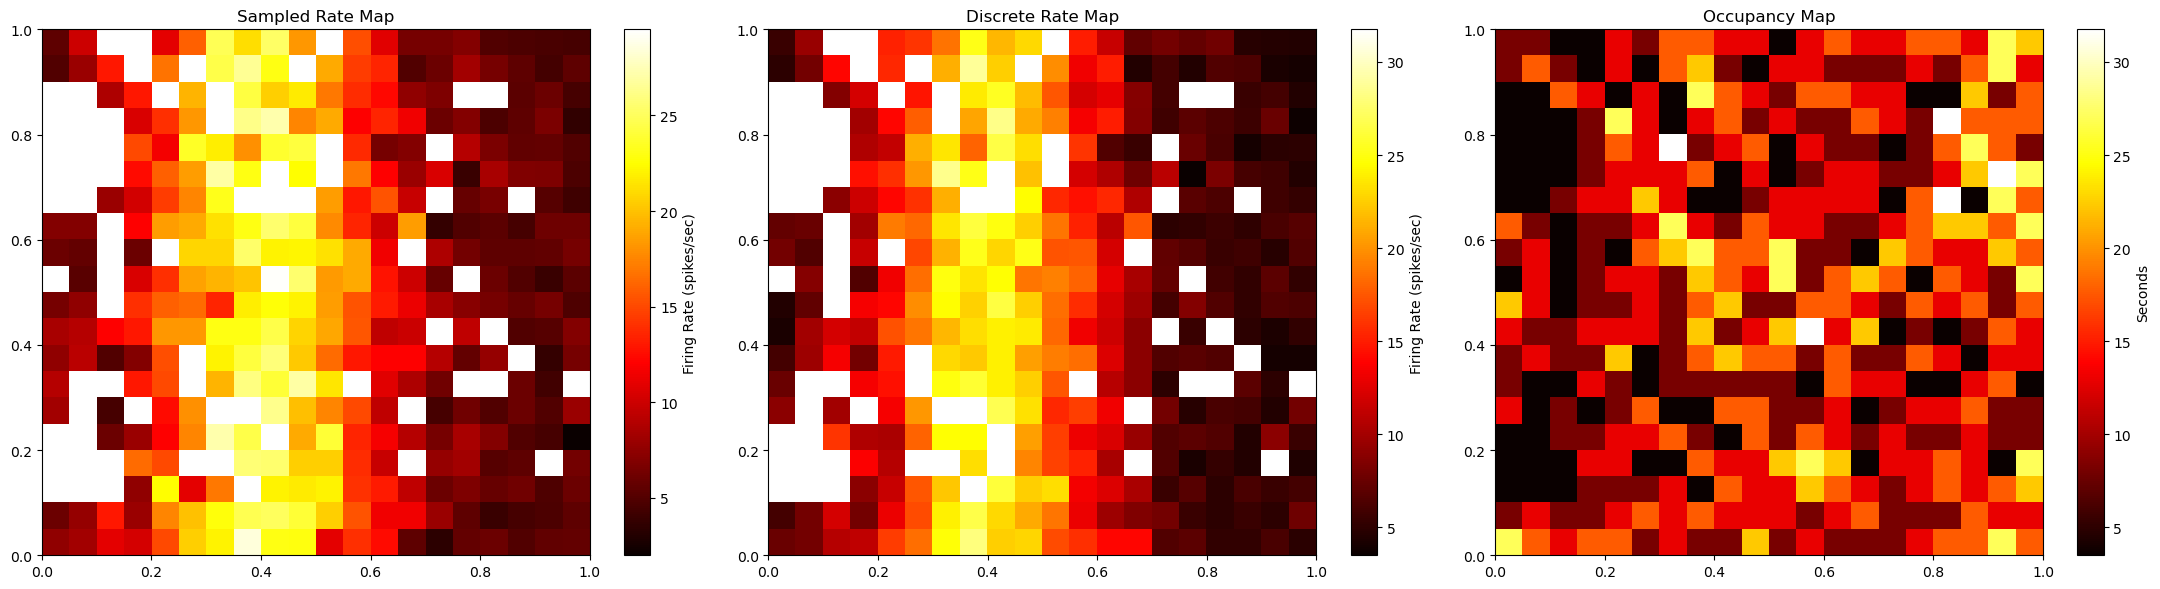

In [262]:
fig, axs = plt.subplots(1, 3, figsize=(22, 6))

# Rate map
im1 = axs[0].imshow(rate_map.T, origin='lower', aspect='auto',
                     extent=[bin_edges[0], bin_edges[-1], bin_edges[0], bin_edges[-1]],
                     cmap='hot')
axs[0].set_title("Sampled Rate Map")
fig.colorbar(im1, ax=axs[0], label='Firing Rate (spikes/sec)')

# Discrete
im2 = axs[1].imshow(rate_map_d.T, origin='lower', aspect='auto',
                     extent=[bin_edges[0], bin_edges[-1], bin_edges[0], bin_edges[-1]],
                     cmap='hot')
axs[1].set_title(f"Discrete Rate Map")
fig.colorbar(im2, ax=axs[1], label='Firing Rate (spikes/sec)')

# Occupancy map
im3 = axs[2].imshow(occ_seconds.T, origin='lower', aspect='auto',
                     extent=[bin_edges[0], bin_edges[-1], bin_edges[0], bin_edges[-1]],
                     cmap='hot')
axs[2].set_title(f"Occupancy Map")
fig.colorbar(im2, ax=axs[2], label='Seconds')

plt.tight_layout()
plt.show()


In [264]:
from src.explained_variance import *
from scipy.ndimage import zoom
from tqdm import tqdm

# there's some variance in the dataset and also between splitting the two folds

n_splits = 300
n_bins = 40

smoother = 2.

ev_nonselect = np.zeros((n_splits))
ev_nonselect_d = np.zeros((n_splits))
ev_nonselect_s = np.zeros((n_splits))

bin_edges = np.linspace(lo, hi, num_bins + 1)

for s in tqdm(range(n_splits)):
    counts, (s1_t, s2_t) = get_counts(num_bins=n_bins, seed=s)
    counts_d, (s1_d, s2_d) = get_counts_discrete(s1_t, s2_t, bin_edges, seed=s)
    
    raw_rate_map, occ = build_raw_visits(s1_t, s2_t, counts, 2, num_bins, bin_edges)
    raw_rate_map_d, occ_d = build_raw_visits(s1_d, s2_d, counts_d, 2, num_bins, bin_edges)
    
    _, fold0, fold1, _, _ = get_splits(raw_rate_map[:, :, :, np.newaxis], seed=s)
    _, fold0_d, fold1_d, _, _ = get_splits(raw_rate_map_d[:, :, :, np.newaxis], seed=s)

    ev_ns = quantify_variance(fold0, fold1, axis=1)[0]
    ev_ss = quantify_variance(fold0, fold1, axis=0)[0]
    
    ev_ns_d = quantify_variance(fold0_d, fold1_d, axis=1)[0]
    ev_ss_d = quantify_variance(fold0_d, fold1_d, axis=0)[0]

    # and then let's demonstrate that smoothing mitigates the effects
    
    fold0_s = nan_aware_gaussian_filter(fold0, sigma=smoother)
    fold1_s = nan_aware_gaussian_filter(fold1, sigma=smoother)

    ev_ns_s = quantify_variance(fold0_s, fold1_s, axis=1)[0]
    ev_ss_s = quantify_variance(fold0_s, fold1_s, axis=0)[0]

    if total_var > 0:
        ev_nonselect[s] = ev_ns / (ev_ss + ev_ns)
        ev_nonselect_d[s] = ev_ns_d / (ev_ss_d + ev_ns_d)
        ev_nonselect_s[s] = ev_ns_s / (ev_ss_s + ev_ns_s)
    else:
        ev_s1[s] = 0
        ev_s2[s] = 0
    

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 300/300 [00:03<00:00, 96.04it/s]


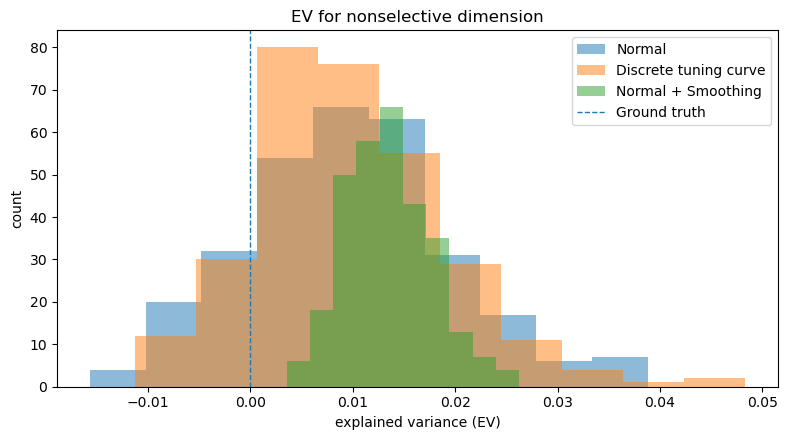

In [265]:

plt.figure(figsize=(8, 4.5))

plt.hist(ev_nonselect, alpha=0.5, label='Normal', histtype='stepfilled')
plt.hist(ev_nonselect_d, alpha=0.5, label='Discrete tuning curve', histtype='stepfilled')
plt.hist(ev_nonselect_s, alpha=0.5, label='Normal + Smoothing', histtype='stepfilled')

plt.axvline(0, linestyle='--', label='Ground truth', linewidth=1)

plt.title(f'EV for nonselective dimension')
plt.xlabel('explained variance (EV)')
plt.ylabel('count')
plt.legend()
plt.tight_layout()
plt.savefig(current_file_path / f'figs/binning_bias_{n_bins}_bins.png', dpi=300)
plt.show()


And now just plot it all together.

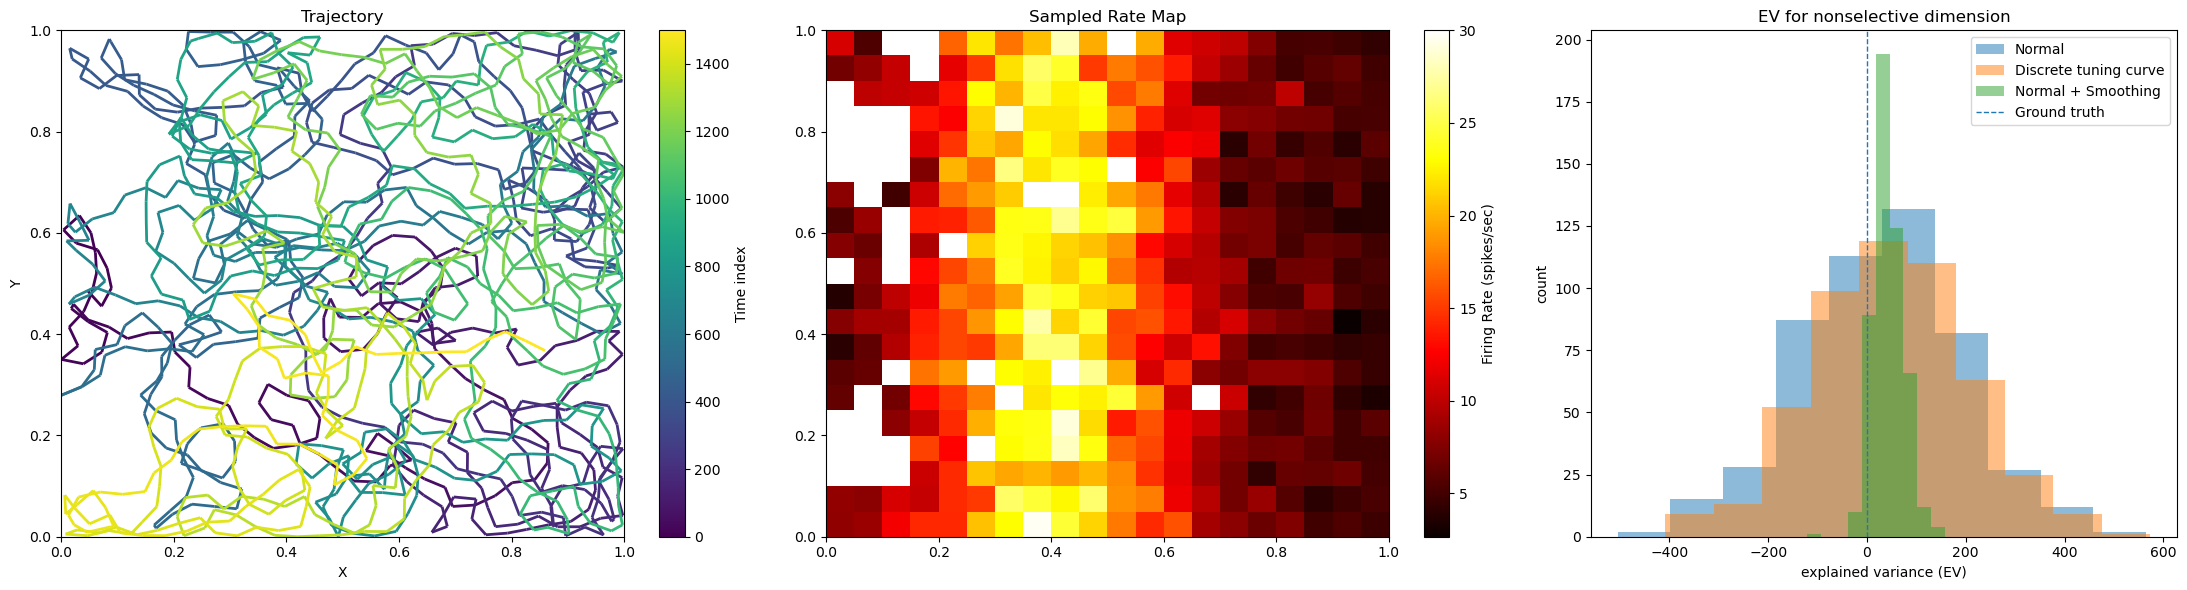

In [232]:
from matplotlib.collections import LineCollection
import matplotlib.pyplot as plt
import numpy as np

x = positions[:, 1]
y = positions[:, 2]
timesteps = positions[:, 0]

points = np.array([x, y]).T.reshape(-1, 1, 2)
segments = np.concatenate([points[:-1], points[1:]], axis=1)

lc = LineCollection(
    segments, cmap='viridis',
    norm=plt.Normalize(timesteps.min(), timesteps.max())
)
lc.set_array(timesteps)
lc.set_linewidth(2)

fig, axs = plt.subplots(
    1, 3, figsize=(22, 6),
    gridspec_kw={'width_ratios': [1.2, 1.2, 1]}
)

line = axs[0].add_collection(lc)
cbar = fig.colorbar(line, ax=axs[0])
cbar.set_label("Time index")
axs[0].set_xlim(0, 1)
axs[0].set_ylim(0, 1)
axs[0].set_xlabel("X")
axs[0].set_ylabel("Y")
axs[0].set_title("Trajectory")

im1 = axs[1].imshow(
    rate_map.T, origin='lower', aspect='auto',
    extent=[bin_edges[0], bin_edges[-1], bin_edges[0], bin_edges[-1]],
    cmap='hot'
)
axs[1].set_title("Sampled Rate Map")
fig.colorbar(im1, ax=axs[1], label='Firing Rate (spikes/sec)')

axs[2].hist(ev_nonselect, alpha=0.5, label='Normal', histtype='stepfilled')
axs[2].hist(ev_nonselect_d, alpha=0.5, label='Discrete tuning curve', histtype='stepfilled')
axs[2].hist(ev_nonselect_s, alpha=0.5, label='Normal + Smoothing', histtype='stepfilled')
axs[2].axvline(0, linestyle='--', label='Ground truth', linewidth=1)
axs[2].set_title('EV for nonselective dimension')
axs[2].set_xlabel('explained variance (EV)')
axs[2].set_ylabel('count')
axs[2].legend()

plt.tight_layout()
plt.savefig(current_file_path / f'figs/binning_bias_full.png', dpi=300)
plt.show()
